<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/main/notebooks/baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature-Based Baseline

This notebook builds a simple feature-based baseline for predicting a child's age from EEG. Each recording is reduced to a small set of hand-crafted features from a single channel, and a linear regression model maps those features to age. The result is the reference point the CNN has to beat.

## Goals

- Compute a constant-age reference (always predicting the training mean/median) on the validation set
- Load channel 14 (C3-P3) for each subject
- Implement Hjorth parameters (activity, mobility, complexity) and test them on synthetic signals
- Implement band-power features (delta, theta, alpha, beta) consistent with the starter implementation
- Build and save feature tables for the training and validation subjects
- Explore how each feature relates to age
- Train a standardized linear regression model on the training set only
- Evaluate on the validation set using MAE and RMSE, and compare with the constant-age reference

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/BrainAge/data"
EEG_DIR = os.path.join(DATA_DIR, "pre_processed")
METADATA_PATH = os.path.join(DATA_DIR, "anon_codex_age_sex.csv")

TRAIN_PATH = os.path.join(DATA_DIR, "segments_h1k_train.pt")
VAL_PATH = os.path.join(DATA_DIR, "segments_h1k_val.pt")
TEST_PATH = os.path.join(DATA_DIR, "segments_h1k_test.pt")

RESAMPLING_RATE = 64   # Hz, as in eda.ipynb
CHANNEL = 14           # C3-P3, chosen in eda.ipynb

In [5]:
print(os.listdir(DATA_DIR))
print("EEG files:", len(os.listdir(EEG_DIR)))

['anon_codex_age_sex.csv', 'segments_h1k_val.pt', 'segments_h1k_train.pt', 'segments_h1k_test.pt', 'pre_processed']
EEG files: 1034


In [6]:
train_data = torch.load(TRAIN_PATH)
val_data = torch.load(VAL_PATH)

print("Train:", len(train_data))
print("Val:", len(val_data))
print(train_data[0])

Train: 825
Val: 103
(0, 901, 0, 5.284383562, '8128DH.edf')


## 1. Constant-age reference: predicting age with no EEG data

In [7]:
from sklearn.metrics import mean_absolute_error

# Ages from each split
y_train = np.array([train_data[i][3] for i in range(len(train_data))])
y_val = np.array([val_data[i][3] for i in range(len(val_data))])

# One constant guess
mean_guess = np.mean(y_train)
median_guess = np.median(y_train)

# Predict that guess for every validation child
pred_mean = np.full(len(y_val), mean_guess)
pred_median = np.full(len(y_val), median_guess)

print("Mean guess:  ", mean_guess, "-> val MAE:", mean_absolute_error(y_val, pred_mean))
print("Median guess:", median_guess, "-> val MAE:", mean_absolute_error(y_val, pred_median))

Mean guess:   4.588638249135758 -> val MAE: 3.4722103478766466
Median guess: 2.975479452 -> val MAE: 2.9775349512330096



By calculating the mean and median ages of the training data to predict the ages in the validation data we get an MAE of 2.98 years when using median age. That means our challenge is to make a baseline model that is more accurate than an MAE of 2.98 years by utilising data found in the EEG.

## 2. Inspecting a single recording (channel 14, C3-P3)

Shape of full recording: torch.Size([20, 57664])
Samples in channel 14: 57664
Duration (s): 901.0


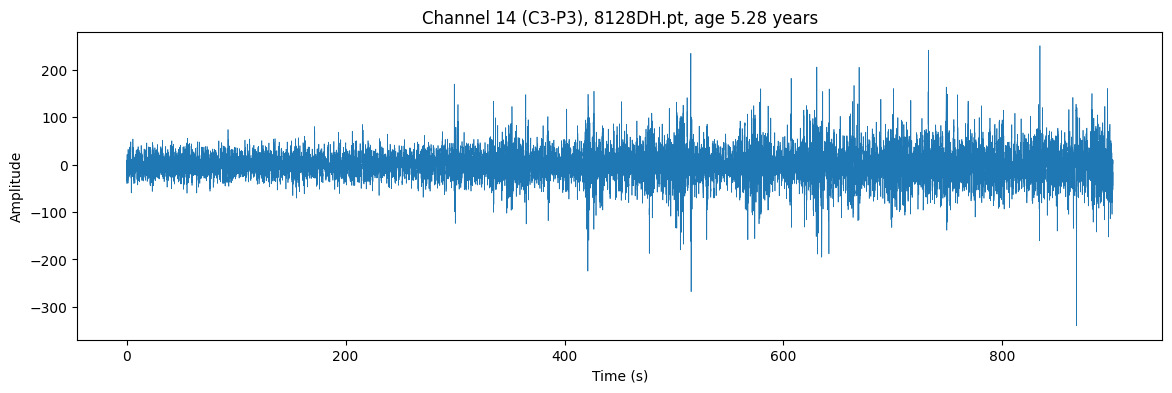

In [8]:
filename = train_data[0][4].replace(".edf",".pt")
path = os.path.join(EEG_DIR, filename)

eeg = torch.load(path).float()
signal = eeg[CHANNEL].numpy()

print("Shape of full recording:", eeg.shape)
print("Samples in channel 14:", len(signal))
print("Duration (s):", len(signal) / RESAMPLING_RATE)

time = np.arange(len(signal)) / RESAMPLING_RATE

plt.figure(figsize=(14, 4))
plt.plot(time, signal, linewidth=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Channel 14 (C3-P3), {filename}, age {train_data[0][3]:.2f} years")
plt.show()

looking at the eeg channel in this recording we can see a change in amplitude around 300s, my best guess as to what causes the change is that's the point in time when the child falls asleep as the rest of the channel has a larger amplitude than the first roughly 300s. We found in the project starter notebook that approximately the first 300s are the pre-N2 onset region (before the children fall into N2 sleep). This area might be a good place to start with a baseline model.

## 4. Feature functions: Hjorth parameters

In [9]:
def mobility(x):
    return np.sqrt(np.var(np.diff(x)) / (np.var(x) + 1e-6))

def hjorth(x):
    # x: 1D numpy array, one channel of EEG
    activity = np.var(x)
    mob = mobility(x)
    complexity = mobility(np.diff(x)) / (mob + 1e-6)
    return activity, mob, complexity

In [10]:
t = np.arange(0, 10, 1/RESAMPLING_RATE)   # 10 seconds of time at 64 Hz
slow = np.sin(2 * np.pi * 2 * t)          # 2 Hz sine
fast = np.sin(2 * np.pi * 10 * t)         # 10 Hz sine
big  = 5 * np.sin(2 * np.pi * 2 * t)      # 2 Hz sine, 5x bigger

for name, sig in [("slow", slow), ("fast", fast), ("big", big)]:
    a, m, c = hjorth(sig)
    print(f"{name:5s}  activity={a:.3f}  mobility={m:.3f}  complexity={c:.3f}")

slow   activity=0.500  mobility=0.196  complexity=1.003
fast   activity=0.500  mobility=0.942  complexity=1.001
big    activity=12.500  mobility=0.196  complexity=1.003


We have set up the hjorth feature calculations and to test if they are correct we used some code generated by claude to see if what should happen actually happens. The expected outcome is that mobility will be highest on the fast wave, activity will be highest on the big wave. The results matched the predicted outcome showing us that our hjorth features are set up correctly.

## 4. Feature functions: band power

In [11]:
from scipy.integrate import simpson
from scipy import signal as sps

# Band edges from the project starter pack
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 12), "beta": (12, 30)}

def band_power(x, fs, low, high, win=4):
    freqs, psd = sps.welch(x, fs, nperseg=win*fs)
    idx = np.logical_and(freqs >= low, freqs <= high)
    freq_res = freqs[1] - freqs[0]
    abs_power = simpson(psd[idx], dx=freq_res)
    total_power = simpson(psd, dx=freq_res)
    return abs_power, abs_power / total_power

In [13]:
for name, sig in [("slow 2 Hz", slow), ("fast 10 Hz", fast)]:
    rel = {b: band_power(sig, RESAMPLING_RATE, lo, hi)[1] for b, (lo, hi) in BANDS.items()}
    print(f"{name:10s}  " + "  ".join(f"{b}={v:.3f}" for b, v in rel.items()))

slow 2 Hz   delta=1.000  theta=0.000  alpha=0.000  beta=0.000
fast 10 Hz  delta=0.000  theta=0.000  alpha=1.000  beta=0.000


Here we split the signals into four sepperate frequency bands. delta, theta, alpha and beta. Each captures a different frequencie of waves from range (delta 0.5–4 Hz, theta 4–8 Hz, alpha 8–12 Hz, beta 12–30 Hz). We then test wether we have implemented it correctly by seeing if these bands capture the right frequencies, slow (2 Hz) and fast (10 hz). Slow belongs to delta, and fast belings to alpha. The test results show that our implementation was correct.

## 5. Building the feature table (first 300 s, channel 14)

In [14]:
from tqdm.auto import tqdm

WINDOW_S = 300   # pre-N2 onset region
FEATURE_DIR = "/content/drive/MyDrive/BrainAge_features"
os.makedirs(FEATURE_DIR, exist_ok=True)

def extract_features(entry):
    fname = entry[4].replace(".edf", ".pt")
    eeg = torch.load(os.path.join(EEG_DIR, fname)).float()
    x = eeg[CHANNEL, :WINDOW_S * RESAMPLING_RATE].numpy()

    activity, mob, complexity = hjorth(x)
    row = {"subject": fname[:-3], "age": entry[3],
           "activity": activity, "mobility": mob, "complexity": complexity}
    for band, (lo, hi) in BANDS.items():
        row[band] = band_power(x, RESAMPLING_RATE, lo, hi)[1]
    row["zeros_in_window"] = int((x == 0).sum())   # sanity check for padding
    return row

train_df = pd.DataFrame([extract_features(e) for e in tqdm(train_data)])
val_df = pd.DataFrame([extract_features(e) for e in tqdm(val_data)])

train_df.to_csv(os.path.join(FEATURE_DIR, "features_train.csv"), index=False)
val_df.to_csv(os.path.join(FEATURE_DIR, "features_val.csv"), index=False)

print(train_df.shape, val_df.shape)
print("NaNs:", train_df.isna().sum().sum(), val_df.isna().sum().sum())
print("Recordings with zeros in window:", (train_df.zeros_in_window > 0).sum())
display(train_df.head())

  0%|          | 0/825 [00:00<?, ?it/s]

  0%|          | 0/103 [00:00<?, ?it/s]

(825, 10) (103, 10)
NaNs: 0 0
Recordings with zeros in window: 0


,subject,age,activity,mobility,complexity,delta,theta,alpha,beta,zeros_in_window
0,8128DH,5.284384,328.900208,0.436994,2.550024,0.599280,0.165636,0.051642,0.031425,0
1,Z5747B,1.047671,3131.830811,0.229566,6.370278,0.320740,0.033697,0.004734,0.009072,0
2,B4432M,0.454207,911.241455,0.322340,2.891117,0.712664,0.138829,0.011367,0.008168,0
3,NI1617,2.975479,4822.700195,0.195008,5.282240,0.501434,0.029891,0.015123,0.004619,0
4,23R3X1,1.787671,4564.287598,0.218446,4.365855,0.334386,0.073907,0.010499,0.004193,0


Here we are translating each childs EEG signal into the 7 features that we will use to have the model predict a childs age. Specifically using the first 300s from channel 14 (C3-P3), the pre N2-onset region. We are then saving the features in a CSV so we don't have to reread all the EEGs and extract the features from them again, instead we can use the CSV.

## 6. How each feature relates to age

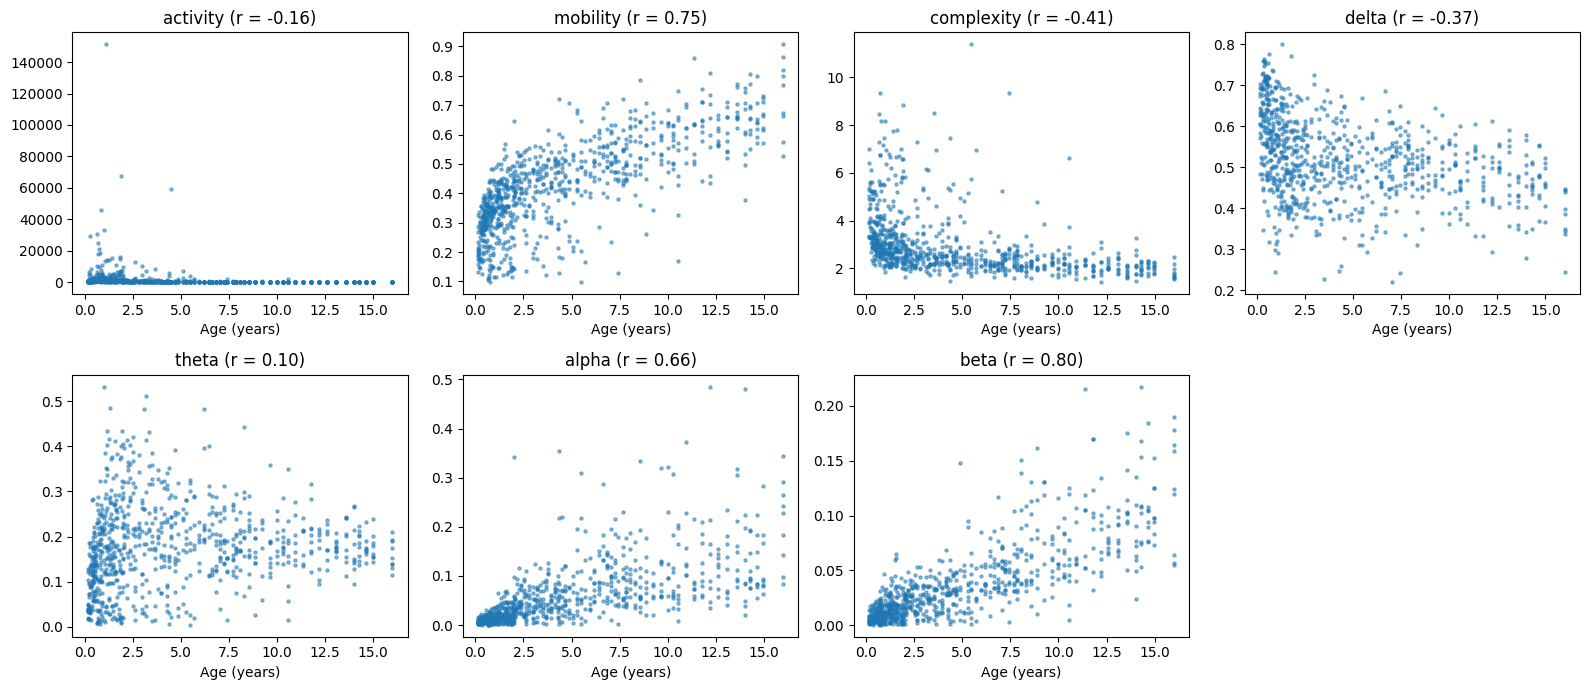

In [15]:
FEATURES = ["activity", "mobility", "complexity", "delta", "theta", "alpha", "beta"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feat in zip(axes.flat, FEATURES):
    ax.scatter(train_df["age"], train_df[feat], s=5, alpha=0.5)
    r = np.corrcoef(train_df["age"], train_df[feat])[0, 1]
    ax.set_title(f"{feat} (r = {r:.2f})")
    ax.set_xlabel("Age (years)")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

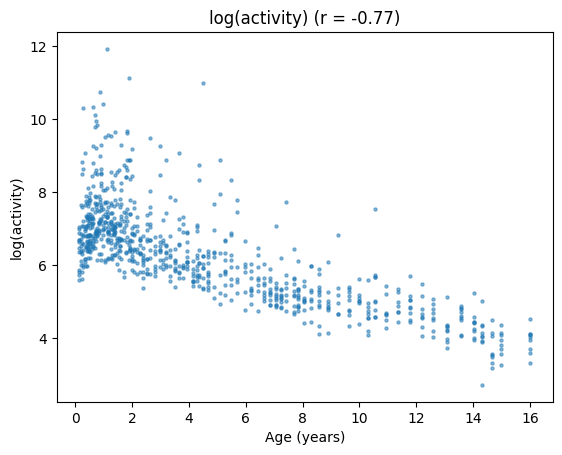

In [16]:
plt.scatter(train_df["age"], np.log(train_df["activity"]), s=5, alpha=0.5)
plt.xlabel("Age (years)"); plt.ylabel("log(activity)")
plt.title(f"log(activity) (r = {np.corrcoef(train_df['age'], np.log(train_df['activity']))[0,1]:.2f})")
plt.show()

In [18]:
train_df["log_activity"] = np.log(train_df["activity"])
val_df["log_activity"] = np.log(val_df["activity"])

We make scatter plots for each feature and calculate it's r value (correlation coefficient) that measures how well the dots line up along a straight line between -1 and +1. -1 means a perfect downward line and 1 means a perfect upward line. Activity looks like it has very little effect by looking at it's first scatter plot but with closer inspection we can see that one massive outlier is skewing the plot extremely much. Using the same idea as log(price) from hw1, we log() the feature, r improved from -0.16 to -0.77 and hopefully this change helps to improve the model. Mobility gets higher with age but changes rapidly in the first few years. Complexity gets lower with age, biggest fall being in the first couple years. Delta gets lower with age but is quite scattered. Theta seems to be the least effective feature with an r value of 0.10, because there are no massive outliers in the data we cannot use the same log() method as we did for activity. Alpha increases with age and Beta is the strongest feature with an r value of 0.8 and increases with age almost linearly. The plots show that power shifts from slow to fast frequencies with age and many relationships are curved meaning the data is not ideal for a linear model.

## 7. Linear regression baseline

Linear regression  val MAE: 1.67 years, RMSE: 2.18 years
Constant (median)  val MAE: 2.98 years


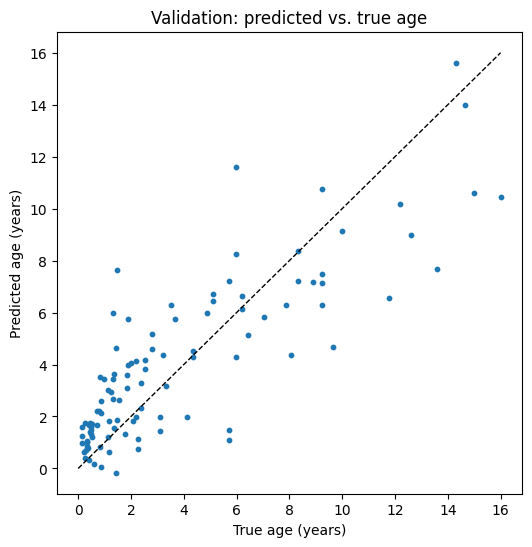

,0
theta,-1.354477
delta,-0.468562
alpha,-0.389460
activity,-0.062623
beta,0.592437
complexity,0.677353
mobility,4.079845


In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

FEATURES = ["activity", "mobility", "complexity", "delta", "theta", "alpha", "beta"]

X_train, y_train = train_df[FEATURES].values, train_df["age"].values
X_val, y_val = val_df[FEATURES].values, val_df["age"].values

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

pred = model.predict(X_val)
mae = mean_absolute_error(y_val, pred)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"Linear regression  val MAE: {mae:.2f} years, RMSE: {rmse:.2f} years")
print(f"Constant (median)  val MAE: {mean_absolute_error(y_val, pred_median):.2f} years")

# Predicted vs true
plt.figure(figsize=(6, 6))
plt.scatter(y_val, pred, s=10)
plt.plot([0, 16], [0, 16], "k--", linewidth=1)
plt.xlabel("True age (years)"); plt.ylabel("Predicted age (years)")
plt.title("Validation: predicted vs. true age")
plt.show()

# Which features does the model lean on?
coefs = model.named_steps["linearregression"].coef_
display(pd.Series(coefs, index=FEATURES).sort_values())

Linear regression (log activity)  val MAE: 1.56 years, RMSE: 2.01 years
Constant (median)  val MAE: 2.98 years


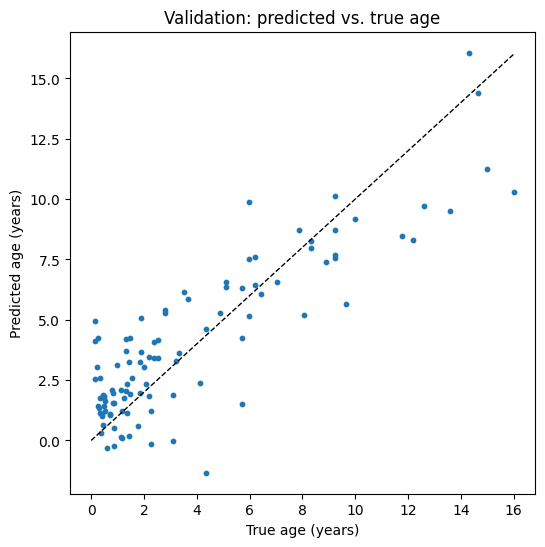

,0
log_activity,-2.298668
delta,-0.447957
theta,-0.317765
mobility,-0.040273
alpha,0.703093
complexity,0.789255
beta,1.654891


In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

FEATURES = ["log_activity", "mobility", "complexity", "delta", "theta", "alpha", "beta"]

X_train, y_train = train_df[FEATURES].values, train_df["age"].values
X_val, y_val = val_df[FEATURES].values, val_df["age"].values

model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

pred = model.predict(X_val)
mae = mean_absolute_error(y_val, pred)
rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"Linear regression (log activity)  val MAE: {mae:.2f} years, RMSE: {rmse:.2f} years")
print(f"Constant (median)  val MAE: {mean_absolute_error(y_val, pred_median):.2f} years")

# Predicted vs true
plt.figure(figsize=(6, 6))
plt.scatter(y_val, pred, s=10)
plt.plot([0, 16], [0, 16], "k--", linewidth=1)
plt.xlabel("True age (years)"); plt.ylabel("Predicted age (years)")
plt.title("Validation: predicted vs. true age")
plt.show()

# Which features does the model lean on?
coefs = model.named_steps["linearregression"].coef_
display(pd.Series(coefs, index=FEATURES).sort_values())

Finally we fit and run the model, once with activity and once with log_activity. We can see that both models are clearly better than the median guess. The activity model has an MAE of 1.67 years and the log_activity model has an MAE of 1.56 years beating the median guesses MAE of 2.98 years comfortably. This shows that the features that we chose for our baseline clearly contain information about a childs age. The improvement for the log_activity model over the activity model is quite modest with an RMSE improvement being only 0.17 years. This could be explained by the fact that our features contain similar information and the log_activity adds only a little bit to what the other features already provide the model. Our model over predicts young children but under predicts older children, this is a problem with linear models for curved data. The largest weightes for our activity model are mobility and theta while activity is almost negligable, for our log_activity model the largest weights are log_activity and beta while mobility is almost negligable. Although the models have similar accuracy they use different features to make their predictions showing that the feature data might hold similar information.